# Tugas Besar 2 IF3170: Prediksi Pembatalan Pemesanan Penginapan

# Initialization

## Import Libraries

In [1]:
import os
import pickle
import random
import time

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## Kode From Scratch

In [2]:
# utils: save/load model, metric evaluasi, dan cross validation

# simpan model ke file pickle
def save_model(model, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, 'wb') as f:
        pickle.dump(model, f)

# load lagi model yang disimpan pakai save_model
def load_model(path):
    with open(path, 'rb') as f:
        return pickle.load(f)

# confusion matrix biner, bentuknya [[TN, FP], [FN, TP]]
def confusion_matrix(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1))); tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1))); fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    return np.array([[tn, fp], [fn, tp]])

# F1 buat class 0 dan class 1, hasilnya [f1_0, f1_1]
def f1_per_class(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix(y_true, y_pred)
    f1_pos = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn > 0 else 0.0
    f1_neg = 2 * tn / (2 * tn + fn + fp) if tn + fn + fp > 0 else 0.0
    return np.array([f1_neg, f1_pos])

# Macro F1, rata-rata F1 dua class (metric kompetisi)
def macro_f1(y_true, y_pred):
    return float(f1_per_class(y_true, y_pred).mean())

# cari threshold dengan Macro F1 paling tinggi dari prediksi out-of-fold
def best_threshold(y_true, proba):
    grid = np.round(np.arange(0.20, 0.81, 0.01), 2)
    scores = [macro_f1(y_true, proba >= t) for t in grid]
    i = int(np.argmax(scores))
    return float(grid[i]), float(scores[i])

# bagi index jadi k fold dengan proporsi class yang sama, hasilnya list (train_idx, val_idx)
def stratified_kfold(y, n_splits=5, seed=42):
    rng = np.random.RandomState(seed)
    fold_of = np.empty(len(y), dtype=int)
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        rng.shuffle(idx)
        fold_of[idx] = np.arange(len(idx)) % n_splits
    return [(np.where(fold_of != k)[0], np.where(fold_of == k)[0]) for k in range(n_splits)]

TARGET = 'is_canceled'
ID_COL = 'id'
CAT_COLS = ['meal_package', 'room_category', 'booking_channel']

# buang row duplikat persis (feature dan target), khusus data train
def clean_train(df):
    feature_cols = [c for c in df.columns if c != ID_COL]
    return df.drop_duplicates(subset=feature_cols).reset_index(drop=True)

# nilai yang nggak masuk akal (num_adults = 0) dijadiin missing
def mark_invalid(df):
    df = df.copy()
    df.loc[df['num_adults'] == 0, 'num_adults'] = np.nan
    return df

## Settings

In [3]:
class Settings:
    SEED = 42
    N_FOLDS = 5
    CHECK_SEEDS = [1, 2, 3, 4, 5]

    # 8 feature hasil forward selection di knn_selection_distance
    BASE_FEATURES = ['days_before_arrival', 'arrival_index', 'special_requests', 'nightly_rate_idr',
                     'booking_channel', 'arrival_dayofyear', 'total_nights', 'needs_parking']
    K = 31
    BATCH = 512

    # baseline: z-score, one-hot 0,5, Manhattan, voting 1/d
    BASE_CFG = {}
    # langkah yang ditambahkan satu per satu
    STEPS = [('Scaling Min-Max', 'scaler', 'minmax'), ('Voting Kernel 1/d²', 'kernel', 'inv2')]
    FINAL_CFG = None

    EXP_NAME = 'knn_minmax'
    MODEL_PATH = f'{EXP_NAME}.pkl'
    SUB_PATH = f'submission_{EXP_NAME}.csv'

CFG = Settings()
CFG.FINAL_CFG = {key: value for _, key, value in CFG.STEPS}

## Seed Everything

In [4]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

In [5]:
train_raw = pd.read_csv('train.csv', dtype={'id': str})
test_raw = pd.read_csv('test.csv', dtype={'id': str})

train = clean_train(train_raw)
y = train[TARGET].to_numpy()
print('train', train.shape, ' test', test_raw.shape)

train (27309, 19)  test (6844, 18)


# Data Preparation

## Feature Engineering

In [6]:
# feature turunan per row, aman dipakai di train dan test secara terpisah
def engineer(df):
    df = mark_invalid(df)
    df['total_nights'] = df['weekend_nights'] + df['weekday_nights']
    arrival = pd.to_datetime(dict(year=df['arrival_year'], month=df['arrival_month'], day=df['arrival_day']),
                             errors='coerce')
    df['arrival_dayofyear'] = arrival.dt.day_of_year.astype(float)
    df['arrival_index'] = (arrival - pd.Timestamp('2023-01-01')).dt.days.astype(float)
    # tanggal booking dibuat = tanggal datang - lead time
    df['booking_index'] = df['arrival_index'] - df['days_before_arrival']
    # hari ke-n dalam setahun dijadiin titik di lingkaran
    df['doy_sin'] = np.sin(2 * np.pi * df['arrival_dayofyear'] / 365.25)
    df['doy_cos'] = np.cos(2 * np.pi * df['arrival_dayofyear'] / 365.25)
    return df

E = engineer(train)
E[['arrival_dayofyear', 'doy_sin', 'doy_cos', 'arrival_index', 'days_before_arrival', 'booking_index']].head()

,arrival_dayofyear,doy_sin,doy_cos,arrival_index,days_before_arrival,booking_index
0,94.0,0.998932,-0.046215,458.0,88.0,370.0
1,213.0,-0.499069,-0.866562,212.0,120.0,92.0
2,241.0,-0.843728,-0.536771,605.0,209.0,396.0
3,226.0,-0.678820,-0.734304,590.0,93.0,497.0
4,245.0,-0.878637,-0.477489,609.0,14.0,595.0


## 3.1 Scaling Min-Max

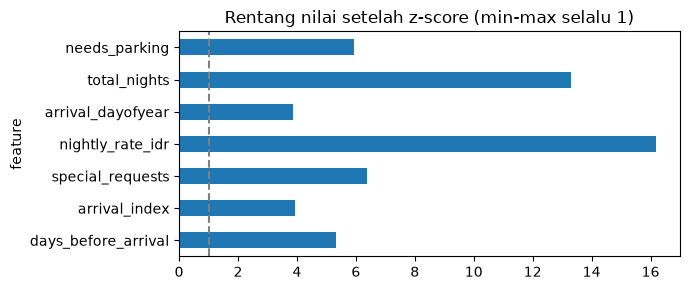

,rentang z-score,skew
feature,,
days_before_arrival,5.32,1.35
arrival_index,3.92,-0.48
special_requests,6.37,1.18
nightly_rate_idr,16.19,0.73
arrival_dayofyear,3.88,-0.33
total_nights,13.29,2.28
needs_parking,5.95,5.61


In [7]:
num = [f for f in Settings.BASE_FEATURES if f not in CAT_COLS]
rows = []
for f in num:
    x = E[f].astype(float).fillna(E[f].median())
    z = (x - x.mean()) / x.std()
    rows.append({'feature': f, 'rentang z-score': z.max() - z.min(), 'skew': x.skew()})
spread = pd.DataFrame(rows).set_index('feature').round(2)

spread['rentang z-score'].plot.barh(figsize=(7, 3), title='Rentang nilai setelah z-score (min-max selalu 1)')
plt.axvline(1, color='gray', ls='--'); plt.tight_layout(); plt.show()
spread

- Setelah z-score, rentang tiap feature beda jauh: nightly_rate_idr 16,2 dan total_nights 13,3, sedangkan arrival_index cuma 3,9 dan arrival_dayofyear 3,9.
- Feature yang skew (total_nights 2,28, needs_parking 5,61) punya outlier yang bikin satu row bisa jauh banget dari row lain cuma karena satu feature.
- Min-max bikin semua feature numerik ada di rentang 0 sampai 1, jadi pengaruh maksimum tiap feature ke jarak sama, dan setara dengan beda kategori di one-hot (0,5 + 0,5 = 1).

## Preprocessor KNN

In [8]:
class KNNPrep:

    def __init__(self, cfg):
        self.cfg = dict(cfg)

    # daftar feature: encoding siklus ganti arrival_dayofyear, booking_index ikut ditambah
    def features(self):
        feats = list(Settings.BASE_FEATURES)
        if self.cfg.get('cyclic'):
            i = feats.index('arrival_dayofyear')
            feats[i:i + 1] = ['doy_sin', 'doy_cos']
        if self.cfg.get('booking'):
            feats.append('booking_index')
        return feats

    # fit statistik dari data train aja: median, center, spread, modus, kategori, cancel rate
    def fit(self, df):
        F = engineer(df)
        y_fit = df[TARGET].to_numpy()
        self.stats_ = {}
        for f in self.features():
            if f in CAT_COLS:
                mode = F[f].mode()[0]
                vals = F[f].fillna(mode)
                if self.cfg.get('vdm'):
                    # VDM: kategori diganti cancel rate-nya, dibagi rentang rate
                    rate = pd.Series(y_fit).groupby(vals.to_numpy()).mean()
                    self.stats_[f] = ('vdm', mode, rate, (rate.max() - rate.min()) or 1.0, y_fit.mean())
                else:
                    self.stats_[f] = ('onehot', mode, sorted(vals.unique()))
                continue
            x = F[f].astype(float)
            med = x.median()
            xf = x.fillna(med)
            if self.cfg.get('scaler') == 'minmax':
                center, spread = xf.min(), xf.max() - xf.min()
            else:
                center, spread = xf.mean(), xf.std()
            self.stats_[f] = ('num', med, center, spread if spread > 0 else 1.0)
        return self

    # pakai statistik yang udah di-fit, hasilnya array float32
    def transform(self, df):
        F = engineer(df)
        cols = []
        for f in self.features():
            st = self.stats_[f]
            if st[0] == 'vdm':
                _, mode, rate, span, prior = st
                cols.append((F[f].fillna(mode).map(rate).fillna(prior) / span).to_numpy())
            elif st[0] == 'onehot':
                # one-hot 0,5: kategori beda jaraknya 0,5 + 0,5 = 1
                _, mode, levels = st
                cols += [((F[f].fillna(mode) == lv) * 0.5).to_numpy() for lv in levels]
            else:
                _, med, center, spread = st
                cols.append(((F[f].astype(float).fillna(med) - center) / spread).to_numpy())
        return np.column_stack(cols).astype(np.float32)

KNNPrep(CFG.FINAL_CFG).fit(train).transform(test_raw)[:3]

array([[0.484375  , 0.74270076, 0.        , 0.14173487, 0.        ,
        0.        , 0.        , 0.5       , 0.        , 0.61263734,
        0.04166667, 0.        ],
       [0.42410713, 0.6459854 , 0.        , 0.21931261, 0.        ,
        0.        , 0.        , 0.        , 0.5       , 0.46703297,
        0.125     , 0.        ],
       [0.2767857 , 0.57664233, 0.2       , 0.20960175, 0.        ,
        0.        , 0.        , 0.        , 0.5       , 0.36263737,
        0.125     , 0.        ]], dtype=float32)

# Modeling dan Validation

## 4.1 KNN from Scratch

In [9]:
class KNN:

    def __init__(self, k=31, p=1, kernel='inv', batch_size=Settings.BATCH):
        self.k, self.p, self.kernel, self.batch_size = k, p, kernel, batch_size

    # lazy learner, cukup simpan data train
    def fit(self, X, y):
        self.X_, self.y_ = np.asarray(X, dtype=np.float32), np.asarray(y).astype(int)
        return self

    # k neighbor terdekat pakai jarak Minkowski p, urut dari yang paling dekat
    def kneighbors(self, Q):
        Q = np.asarray(Q, dtype=np.float32)
        all_d, all_i = [], []
        for s in range(0, len(Q), self.batch_size):
            q = Q[s:s + self.batch_size]
            D = np.zeros((len(q), len(self.X_)), np.float32)
            for j in range(self.X_.shape[1]):
                diff = np.abs(q[:, j, None] - self.X_[None, :, j])
                D += diff if self.p == 1 else diff ** self.p
            idx = np.argpartition(D, self.k - 1, axis=1)[:, :self.k]
            d = np.take_along_axis(D, idx, 1)
            order = np.argsort(d, axis=1, kind='stable')
            all_i.append(np.take_along_axis(idx, order, 1))
            all_d.append(np.take_along_axis(d, order, 1) ** (1 / self.p))
        return np.vstack(all_d), np.vstack(all_i)

    # probabilitas batal dari vote neighbor, weight 1/d atau 1/d^2
    def predict_proba(self, Q):
        d, idx = self.kneighbors(Q)
        w = 1.0 / (d ** 2 + 1e-6) if self.kernel == 'inv2' else 1.0 / (d + 1e-6)
        return (w * self.y_[idx]).sum(1) / w.sum(1)

    # label 0/1 berdasarkan threshold
    def predict(self, Q, threshold=0.5):
        return (self.predict_proba(Q) >= threshold).astype(int)

toy = KNN(k=3, p=1).fit([[0, 0], [0, 1], [5, 5], [5, 6]], [0, 0, 1, 1])
toy.kneighbors([[4, 5]]), toy.predict_proba([[4, 5]])

((array([[1., 2., 8.]], dtype=float32), array([[2, 3, 1]])),
 array([0.92307687]))

## 4.2 Skema Validasi

In [10]:
CACHE = {}

def make_knn(cfg):
    return KNN(k=Settings.K, p=cfg.get('p', 1), kernel=cfg.get('kernel', 'inv'))

# OOF 5 fold buat satu cfg dan satu seed, hasilnya (threshold, Macro F1, proba)
def oof_score(cfg, seed=CFG.SEED):
    key = (repr(sorted(cfg.items())), seed)
    if key not in CACHE:
        oof = np.zeros(len(y))
        for tr, va in stratified_kfold(y, CFG.N_FOLDS, seed):
            prep = KNNPrep(cfg).fit(train.iloc[tr])
            knn = make_knn(cfg).fit(prep.transform(train.iloc[tr]), y[tr])
            oof[va] = knn.predict_proba(prep.transform(train.iloc[va]))
        CACHE[key] = (*best_threshold(y, oof), oof)
    return CACHE[key]

t, s, _ = oof_score(CFG.BASE_CFG)
print(f'baseline (z-score, Manhattan, 1/d, k {Settings.K}): OOF {s:.4f}, threshold {t}')

baseline (z-score, Manhattan, 1/d, k 31): OOF 0.8400, threshold 0.48


## 4.3 Voting Kernel 1/d²

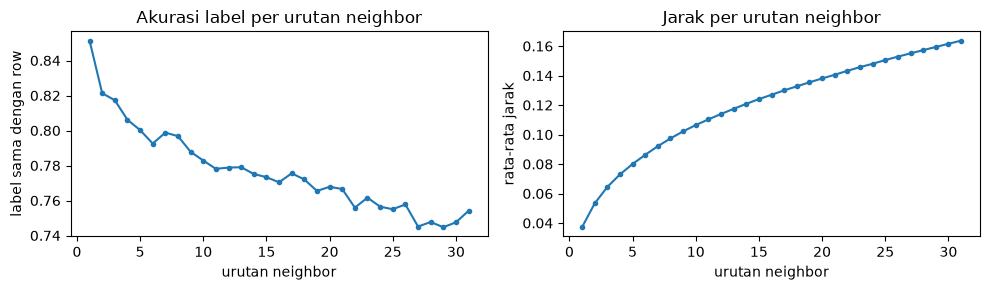

,label sama (neighbor 1),label sama (neighbor 31),"weight n1/nK, 1/d","weight n1/nK, 1/d^2"
0,0.851,0.754,5.188,26.757


In [11]:
# pakai cfg langkah sebelum kernel
knn_cfg = {k: v for k, v in CFG.FINAL_CFG.items() if k != 'kernel'}
tr, va = stratified_kfold(y, CFG.N_FOLDS, CFG.SEED)[0]
prep = KNNPrep(knn_cfg).fit(train.iloc[tr])
d, idx = make_knn(knn_cfg).fit(prep.transform(train.iloc[tr]), y[tr]).kneighbors(prep.transform(train.iloc[va]))
agree = (y[tr][idx] == y[va][:, None]).mean(0)

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(range(1, Settings.K + 1), agree, marker='o', ms=3)
ax[0].set_xlabel('urutan neighbor'); ax[0].set_ylabel('label sama dengan row'); ax[0].set_title('Akurasi label per urutan neighbor')
ax[1].plot(range(1, Settings.K + 1), d.mean(0), marker='o', ms=3)
ax[1].set_xlabel('urutan neighbor'); ax[1].set_ylabel('rata-rata jarak'); ax[1].set_title('Jarak per urutan neighbor')
plt.tight_layout(); plt.show()

ratio = lambda w: np.median(w[:, 0] / w[:, -1])
pd.DataFrame({'label sama (neighbor 1)': [agree[0]], f'label sama (neighbor {Settings.K})': [agree[-1]],
              'weight n1/nK, 1/d': [ratio(1 / (d + 1e-6))], 'weight n1/nK, 1/d^2': [ratio(1 / (d ** 2 + 1e-6))]}).round(3)

- Neighbor terdekat labelnya sama dengan row yang diprediksi 85,1%, neighbor ke-31 cuma 75,4%, jadi makin jauh neighbor-nya makin kurang bisa dipercaya.
- Dengan 1/d, neighbor pertama cuma sekitar 5,2x lebih berpengaruh dari neighbor ke-31, dengan 1/d² sekitar 26,8x. Neighbor jauh tetap ikut vote tapi suaranya kecil.
- Karena itu k bisa dibikin besar (31) tanpa bikin prediksi kabur.

## 4.4 Validasi Tiap Langkah

In [12]:
rows, cfg = [], dict(CFG.BASE_CFG)
t, s, _ = oof_score(cfg)
rows.append({'langkah': 'baseline', 'OOF Macro F1': s, 'threshold': t})
for name, key, value in CFG.STEPS:
    cfg = {**cfg, key: value}
    t, s, _ = oof_score(cfg)
    rows.append({'langkah': f'+ {name}', 'OOF Macro F1': s, 'threshold': t})
steps = pd.DataFrame(rows).set_index('langkah')
steps['selisih'] = steps['OOF Macro F1'].diff()

KNN_THRESHOLD, _, oof_knn = oof_score(CFG.FINAL_CFG)
steps.round(4)

,OOF Macro F1,threshold,selisih
langkah,,,
baseline,0.8400,0.48,NaN
+ Scaling Min-Max,0.8414,0.45,0.0013
+ Voting Kernel 1/d²,0.8440,0.48,0.0026


- Min-max menaikkan OOF +0,0013 (0,8400 ke 0,8414).
- Kernel 1/d² menaikkan OOF +0,0026 (0,8414 ke 0,8440).

## 4.5 Cek dengan Pembagian Fold Lain

In [13]:
rows = []
for seed in CFG.CHECK_SEEDS:
    rows.append({'seed': seed, 'baseline': oof_score(CFG.BASE_CFG, seed)[1], CFG.EXP_NAME: oof_score(CFG.FINAL_CFG, seed)[1]})
seeds = pd.DataFrame(rows).set_index('seed')
seeds['selisih'] = seeds[CFG.EXP_NAME] - seeds['baseline']
print(CFG.EXP_NAME, 'unggul di', int((seeds['selisih'] > 0).sum()), 'dari', len(seeds), 'seed')
print(seeds.mean().round(4).to_string())
seeds.round(4)

knn_minmax unggul di 5 dari 5 seed
baseline      0.8412
knn_minmax    0.8452
selisih       0.0040


,baseline,knn_minmax,selisih
seed,,,
1,0.8412,0.8453,0.0041
2,0.8413,0.8446,0.0033
3,0.8394,0.8448,0.0054
4,0.8431,0.8458,0.0027
5,0.8411,0.8456,0.0046


# Error Analysis

## Confusion Matrix

In [14]:
pred = (oof_knn >= KNN_THRESHOLD).astype(int)
print('confusion matrix [[TN, FP], [FN, TP]]')
print(confusion_matrix(y, pred))
print('F1 kelas 0, kelas 1', f1_per_class(y, pred).round(4))

confusion matrix [[TN, FP], [FN, TP]]
[[16656  1709]
 [ 2011  6933]]
F1 kelas 0, kelas 1 [0.8995 0.7885]


## Kesalahan per Kelompok

In [15]:
def error_by(column, bins=None):
    values = train[column] if bins is None else pd.qcut(train[column], bins, duplicates='drop')
    frame = pd.DataFrame({column: values, 'error': pred != y})
    return frame.groupby(column, observed=True, dropna=False)['error'].agg(['mean', 'size']).round(3)

error_by('booking_channel')

,mean,size
booking_channel,,
Airline,0.239,88
Complimentary,0.000,300
Corporate,0.083,1512
Offline Agent,0.073,7902
Online Travel Agent,0.171,17507


In [16]:
error_by('days_before_arrival', bins=5)

,mean,size
days_before_arrival,,
"(-0.001, 11.0]",0.088,5286
"(11.0, 39.0]",0.140,5332
"(39.0, 80.0]",0.156,5186
"(80.0, 151.0]",0.185,5180
"(151.0, 448.0]",0.092,5205
NaN,0.229,1120


In [17]:
error_by('special_requests')

,mean,size
special_requests,,
0.0,0.144,12678
1.0,0.151,8323
2.0,0.075,3246
3.0,0.004,496
4.0,0.000,60
5.0,0.000,7
NaN,0.160,2499


## Proposed Improvements

- Cuma dua langkah (min-max + kernel 1/d²) sudah unggul di 5 dari 5 seed, rata-rata 0,8452 vs baseline 0,8412 (+0,0040), hampir sama dengan kombinasi 4 langkah.
- Ini kombinasi paling simpel, jadi paling gampang dijelaskan dan paling kecil risiko overfit ke fold.
- Saran: tambah booking_index dan p 0,75 satu per satu di atas kombinasi ini, lalu cek apakah kenaikannya konsisten di 5 seed.
- Saran: coba feature weight per feature, karena min-max bikin semua feature punya rentang sama padahal pentingnya beda.

# Submission

## 6.1 Training Final

In [18]:
prep_final = KNNPrep(CFG.FINAL_CFG).fit(train)
knn_final = make_knn(CFG.FINAL_CFG).fit(prep_final.transform(train), y)
print('cfg', CFG.FINAL_CFG, ' threshold', KNN_THRESHOLD)

cfg {'scaler': 'minmax', 'kernel': 'inv2'}  threshold 0.48


## 6.2 Save dan Load Model

In [19]:
save_model({'preprocessor': prep_final, 'model': knn_final, 'threshold': KNN_THRESHOLD}, CFG.MODEL_PATH)
bundle = load_model(CFG.MODEL_PATH)
print('model tersimpan di', CFG.MODEL_PATH)

model tersimpan di knn_minmax.pkl


## 6.3 Prediksi dan File Submission

In [20]:
X_test = bundle['preprocessor'].transform(test_raw)
test_pred = bundle['model'].predict(X_test, threshold=bundle['threshold'])

submission = pd.DataFrame({'id': test_raw['id'], 'is_canceled': test_pred})
submission.to_csv(CFG.SUB_PATH, index=False)
submission['is_canceled'].value_counts(normalize=True).round(4)

is_canceled
0    0.6923
1    0.3077
Name: proportion, dtype: float64